# Does algorithmic trading improve liquidity?

## Setup

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

In [2]:
import sys, json
from pathlib import Path
import pandas as pd, numpy as np
colab_project = Path('/content/drive/MyDrive/Research_Seminar_AT')
PROJECT = colab_project if colab_project.exists() else Path.cwd()
sys.path.insert(0, str(PROJECT / 'code'))
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
RAW, PROC, RES = PROJECT / 'raw_data', PROJECT / 'processed_data', PROJECT / 'results'

## Data

In [3]:
for f in sorted(RAW.glob('*.csv.gz')):
    print(f.name, '|', round(f.stat().st_size / 1024**2, 2), 'MB')

LOBSTER_AAPL_compact.csv.gz | 4.48 MB
LOBSTER_AMZN_compact.csv.gz | 3.04 MB
LOBSTER_GOOG_compact.csv.gz | 1.7 MB
LOBSTER_INTC_compact.csv.gz | 6.83 MB
LOBSTER_MSFT_compact.csv.gz | 7.35 MB


In [4]:
from at_liquidity.io import load_raw
raw = load_raw(RAW)
msg = raw['AAPL']
print('AAPL messages:', len(msg))
msg.head()

AAPL messages: 400391


,time,type,order_id,size,price,direction,ask1,asksize1,bid1,bidsize1,mid,pre_ask1,pre_bid1,pre_asksize1,pre_bidsize1,pre_mid
0,34200.004241,1,16113575,18,585.33,1,585.94,200,585.33,18,585.635,NaN,NaN,NaN,NaN,NaN
1,34200.004261,1,16113584,18,585.32,1,585.94,200,585.33,18,585.635,585.94,585.33,200.0,18.0,585.635
2,34200.004447,1,16113594,18,585.31,1,585.94,200,585.33,18,585.635,585.94,585.33,200.0,18.0,585.635
3,34200.025552,1,16120456,18,585.91,-1,585.91,18,585.33,18,585.620,585.94,585.33,200.0,18.0,585.635
4,34200.025580,1,16120480,18,585.92,-1,585.91,18,585.33,18,585.620,585.91,585.33,18.0,18.0,585.620


In [5]:
pd.DataFrame({t: m['type'].value_counts().sort_index() for t, m in raw.items()})

,AAPL,AMZN,GOOG,INTC,MSFT
type,,,,,
1,191015,131954,71258,304790,329566
2,3260,2917,19,8028,5602
3,171126,123458,64961,278739,300183
4,23658,8974,7765,28924,29798
5,11332,2445,3913,3559,3616


## Data checks

In [6]:
for t, m in raw.items():
    assert m['time'].is_monotonic_increasing
    ok = (m['ask1'] > m['bid1']).mean()
    print(f'{t}: {len(m):>7,} messages, time monotonic, ask > bid in {ok:.2%} of rows')

AAPL: 400,391 messages, time monotonic, ask > bid in 100.00% of rows
AMZN: 269,748 messages, time monotonic, ask > bid in 100.00% of rows
GOOG: 147,916 messages, time monotonic, ask > bid in 100.00% of rows
INTC: 624,040 messages, time monotonic, ask > bid in 100.00% of rows
MSFT: 668,765 messages, time monotonic, ask > bid in 100.00% of rows


In [7]:
print(json.dumps(json.loads((RES / 'checks.json').read_text()), indent=1))

{
 "AAPL": {
  "trades": 24861,
  "identity_max_gap_bps": 7.105427357601002e-15,
  "share_on_correct_side": 0.953421020876071,
  "share_inside_spread": 0.34226298218092593
 },
 "AMZN": {
  "trades": 8182,
  "identity_max_gap_bps": 1.4210854715202004e-14,
  "share_on_correct_side": 0.9722561720850648,
  "share_inside_spread": 0.2830603764360792
 },
 "GOOG": {
  "trades": 7982,
  "identity_max_gap_bps": 7.105427357601002e-15,
  "share_on_correct_side": 0.967677273866199,
  "share_inside_spread": 0.3388874968679529
 },
 "INTC": {
  "trades": 10369,
  "identity_max_gap_bps": 7.105427357601002e-15,
  "share_on_correct_side": 0.9995177934227023,
  "share_inside_spread": 0.2816086411418652
 },
 "MSFT": {
  "trades": 10184,
  "identity_max_gap_bps": 1.4210854715202004e-14,
  "share_on_correct_side": 0.9990180675569521,
  "share_inside_spread": 0.264630793401414
 },
 "simulated_var": {
  "true_impulse_bps": 2.0,
  "estimated_impulse_bps": 1.99812853339759,
  "true_trade_share": 0.77133261446088

## Trades and spreads

In [8]:
from at_liquidity.trades import build_trades, trade_measures
tr = build_trades(raw['AAPL'])
tm = trade_measures(tr)
pd.concat([tr[['time','q','size','price','bid','ask','mid','mid_5m']], tm], axis=1).head()

,time,q,size,price,bid,ask,mid,mid_5m,qspread,qdepth,espread,rspread_5m,adv_sel_5m,rspread_30m,adv_sel_30m
0,34200.275016,1,65,585.743846,585.73,585.74,585.735,587.3,0.085363,17.572100,0.151027,-26.567541,26.718567,-3.434213,3.585239
1,34200.275057,-1,1,585.730000,585.73,585.75,585.740,587.3,0.170724,22.551175,0.170724,26.803701,-26.632977,3.670571,-3.499846
2,34200.275063,-1,10,585.730000,585.73,585.75,585.740,587.3,0.170724,22.258310,0.170724,26.803701,-26.632977,3.670571,-3.499846
3,34200.275072,1,760,585.874868,585.73,585.75,585.740,587.3,0.170724,19.329660,2.302530,-24.330447,26.632977,-1.197316,3.499846
4,34200.358687,1,4,585.930000,585.77,585.93,585.850,587.3,1.365537,53.025225,1.365537,-23.384825,24.750363,-0.256038,1.621575


In [9]:
ok = tm[['rspread_5m','adv_sel_5m']].notna().all(axis=1)
print('max |espread - rspread - adv_sel| =', (tm.espread - tm.rspread_5m - tm.adv_sel_5m)[ok].abs().max())

max |espread - rspread - adv_sel| = 7.105427357601002e-15


## Panel

In [10]:
p = pd.read_csv(PROC / 'panel_main_prepared.csv')
print(p.shape)
p[['ticker','clock','messages','algo_trad','qspread','espread','rspread_5m','adv_sel_5m','impulse_response','fleet_100ms']].head()

(195, 38)


,ticker,clock,messages,algo_trad,qspread,espread,rspread_5m,adv_sel_5m,impulse_response,fleet_100ms
0,AAPL,9.500000,1390.6,-56.905953,1.673228,1.448978,2.648566,-1.199588,1.209160,0.415167
1,AAPL,9.666667,940.3,-42.134536,1.241276,1.004577,2.465416,-1.460838,0.778742,0.310383
2,AAPL,9.833333,1178.2,-38.297093,1.064631,0.973945,3.306105,-2.332160,0.796567,0.277440
3,AAPL,10.000000,1911.9,-37.534089,1.265864,1.046276,0.491269,0.555007,0.724980,0.318594
4,AAPL,10.166667,1091.2,-34.936488,1.050229,0.786062,-0.345244,1.131306,0.867188,0.338961


## Summary statistics

In [11]:
pd.read_csv(RES / 'table1_summary.csv', index_col=0).round(3)

,AAPL,AMZN,GOOG,INTC,MSFT,All,within_sd
qspread,9.880000e-01,2.349,1.854000e+00,1.951,1.698,1.768000e+00,4.290000e-01
qdepth,1.569720e+02,76.943,1.095160e+02,373.247,353.779,2.140910e+02,1.093460e+02
espread,7.870000e-01,2.138,1.598000e+00,1.734,1.592,1.570000e+00,3.620000e-01
rspread_5m,5.430000e-01,-0.283,3.170000e-01,-1.372,-1.358,-4.310000e-01,2.378000e+00
adv_sel_5m,2.430000e-01,2.383,1.277000e+00,3.104,2.950,1.991000e+00,2.381000e+00
rspread_30m,-4.500000e-01,-1.169,9.780000e-01,-2.791,0.241,-6.380000e-01,6.192000e+00
adv_sel_30m,1.250000e+00,3.362,6.490000e-01,4.514,1.353,2.226000e+00,6.165000e+00
messages,1.026644e+03,691.662,3.793290e+02,1584.458,1714.782,1.079375e+03,4.779800e+02
algo_trad,-3.891400e+01,-6.386,-2.511100e+01,-4.232,-4.492,-1.582700e+01,8.372000e+00
dollar_volume,4.258580e+07,4628257.054,1.031009e+07,7244201.048,8464739.333,1.464662e+07,1.441971e+07


## OLS regressions

In [12]:
ols = pd.read_csv(RES / 'ols_algo_trad.csv')
ols[ols.group == 'High-price'][['table','dep','coef','t','paper_coef','paper_t','same_sign']].round(3)

,table,dep,coef,t,paper_coef,paper_t,same_sign
13,III,qspread,-0.010,-1.704,-0.53,-3.23,True
14,III,qdepth,-3.324,-1.692,-3.49,-2.51,True
15,III,espread,-0.014,-2.900,-0.18,-2.67,True
16,III,rspread_5m,0.021,1.143,0.35,3.52,True
17,III,adv_sel_5m,-0.032,-1.649,-0.53,-3.56,True
18,III,rspread_30m,-0.015,-0.186,0.33,2.82,False
19,III,adv_sel_30m,0.006,0.069,-0.51,-3.43,False
20,IV,turnover,-0.025,-7.247,0.04,1.02,False
21,IV,trades,-0.641,-4.367,0.58,2.60,False
22,IV,trade_size,-0.406,-2.864,-2.04,-4.64,True


In [13]:
msg_ols = pd.read_csv(RES / 'ols_log_messages.csv')
msg_ols[msg_ols.group == 'High-price'][['table','dep','coef','t','paper_coef','same_sign']].round(3)

,table,dep,coef,t,paper_coef,same_sign
13,III,qspread,-0.335,-2.245,-0.53,True
14,III,qdepth,-20.217,-0.306,-3.49,True
15,III,espread,-0.316,-2.335,-0.18,True
16,III,rspread_5m,3.224,4.181,0.35,True
17,III,adv_sel_5m,-3.515,-4.551,-0.53,True
18,III,rspread_30m,1.739,0.563,0.33,True
19,III,adv_sel_30m,-2.035,-0.668,-0.51,True
20,IV,turnover,0.448,1.924,0.04,True
21,IV,trades,28.289,3.735,0.58,True
22,IV,trade_size,4.740,1.241,-2.04,False


In [14]:
pd.DataFrame(json.loads((RES / 'results.json').read_text())['sign_match']).T

,same,of,same_and_sig,opposite_and_sig
algo_trad_All,8,13,3,2
algo_trad_High-price,9,13,2,2
algo_trad_Low-price,5,13,1,3
log_messages_All,9,13,4,1
log_messages_High-price,10,13,5,0
log_messages_Low-price,7,13,3,2


## Instrumental variables

In [15]:
pd.read_csv(RES / 'table2_first_stage.csv').round(3)

,group,dep,instrument,coef,t,F,n
0,All,algo_trad,inst_algo,-2.294,-1.788,3.195,195
1,All,messages,inst_algo,-275.596,-3.764,14.171,195
2,All,log_messages,inst_msg,0.071,1.327,1.762,195
3,All,turnover,inst_algo,-0.741,-4.577,20.948,195
4,All,volatility,inst_algo,-0.031,-1.171,1.371,195
5,All,volatility,inst_msg,0.051,2.888,8.342,195
6,High-price,algo_trad,inst_algo,-3.155,-1.769,3.130,117
7,High-price,messages,inst_algo,-122.390,-5.417,29.342,117
8,High-price,log_messages,inst_msg,0.095,1.399,1.958,117
9,High-price,turnover,inst_algo,-0.687,-6.981,48.735,117


In [16]:
iv = pd.read_csv(RES / 'iv_2sls.csv')
iv[iv.group == 'High-price'][['at','dep','coef','t','F','paper_coef']].round(3)

,at,dep,coef,t,F,paper_coef
10,algo_trad,qspread,0.054,0.762,3.130,-0.53
11,algo_trad,qdepth,-6.379,-1.541,3.130,-3.49
12,algo_trad,espread,0.026,0.561,3.130,-0.18
13,algo_trad,rspread_5m,-0.245,-1.363,3.130,0.35
14,algo_trad,adv_sel_5m,0.266,1.359,3.130,-0.53
15,algo_trad,rspread_30m,-0.438,-0.060,3.130,0.33
16,algo_trad,adv_sel_30m,-0.300,-0.057,3.130,-0.51
17,algo_trad,impulse_response,-0.030,-0.635,3.130,-0.54
18,algo_trad,sd_tradecorr,-0.363,-0.949,3.130,-0.22
19,algo_trad,sd_nontradecorr,-0.344,-1.533,3.130,0.12


## Extension: algorithms in the data

In [17]:
pd.read_csv(RES / 'at_proxy_correlations_main.csv', index_col=0).round(2)

,algo_trad,messages,cancel_to_trade,fleet_100ms,fleet_1000ms,turnover,volatility
algo_trad,1.00,-0.24,0.36,-0.08,-0.10,-0.68,-0.21
messages,-0.24,1.00,-0.39,0.45,0.55,0.70,0.53
cancel_to_trade,0.36,-0.39,1.00,-0.14,-0.18,-0.56,-0.20
fleet_100ms,-0.08,0.45,-0.14,1.00,0.91,0.22,0.41
fleet_1000ms,-0.10,0.55,-0.18,0.91,1.00,0.33,0.45
turnover,-0.68,0.70,-0.56,0.22,0.33,1.00,0.37
volatility,-0.21,0.53,-0.20,0.41,0.45,0.37,1.00


In [18]:
pd.DataFrame(json.loads((RES / 'summary.json').read_text())['order_lifetimes']).T.round(3)

,submitted,cancelled_unfilled,cancelled_within_100ms,cancelled_within_1s,cancelled_within_10ms
AAPL,191015.0,0.859,0.308,0.592,0.189
AMZN,131954.0,0.887,0.272,0.472,0.163
GOOG,71258.0,0.868,0.228,0.380,0.138
INTC,304790.0,0.908,0.355,0.464,0.292
MSFT,329566.0,0.904,0.349,0.443,0.283


## Figures

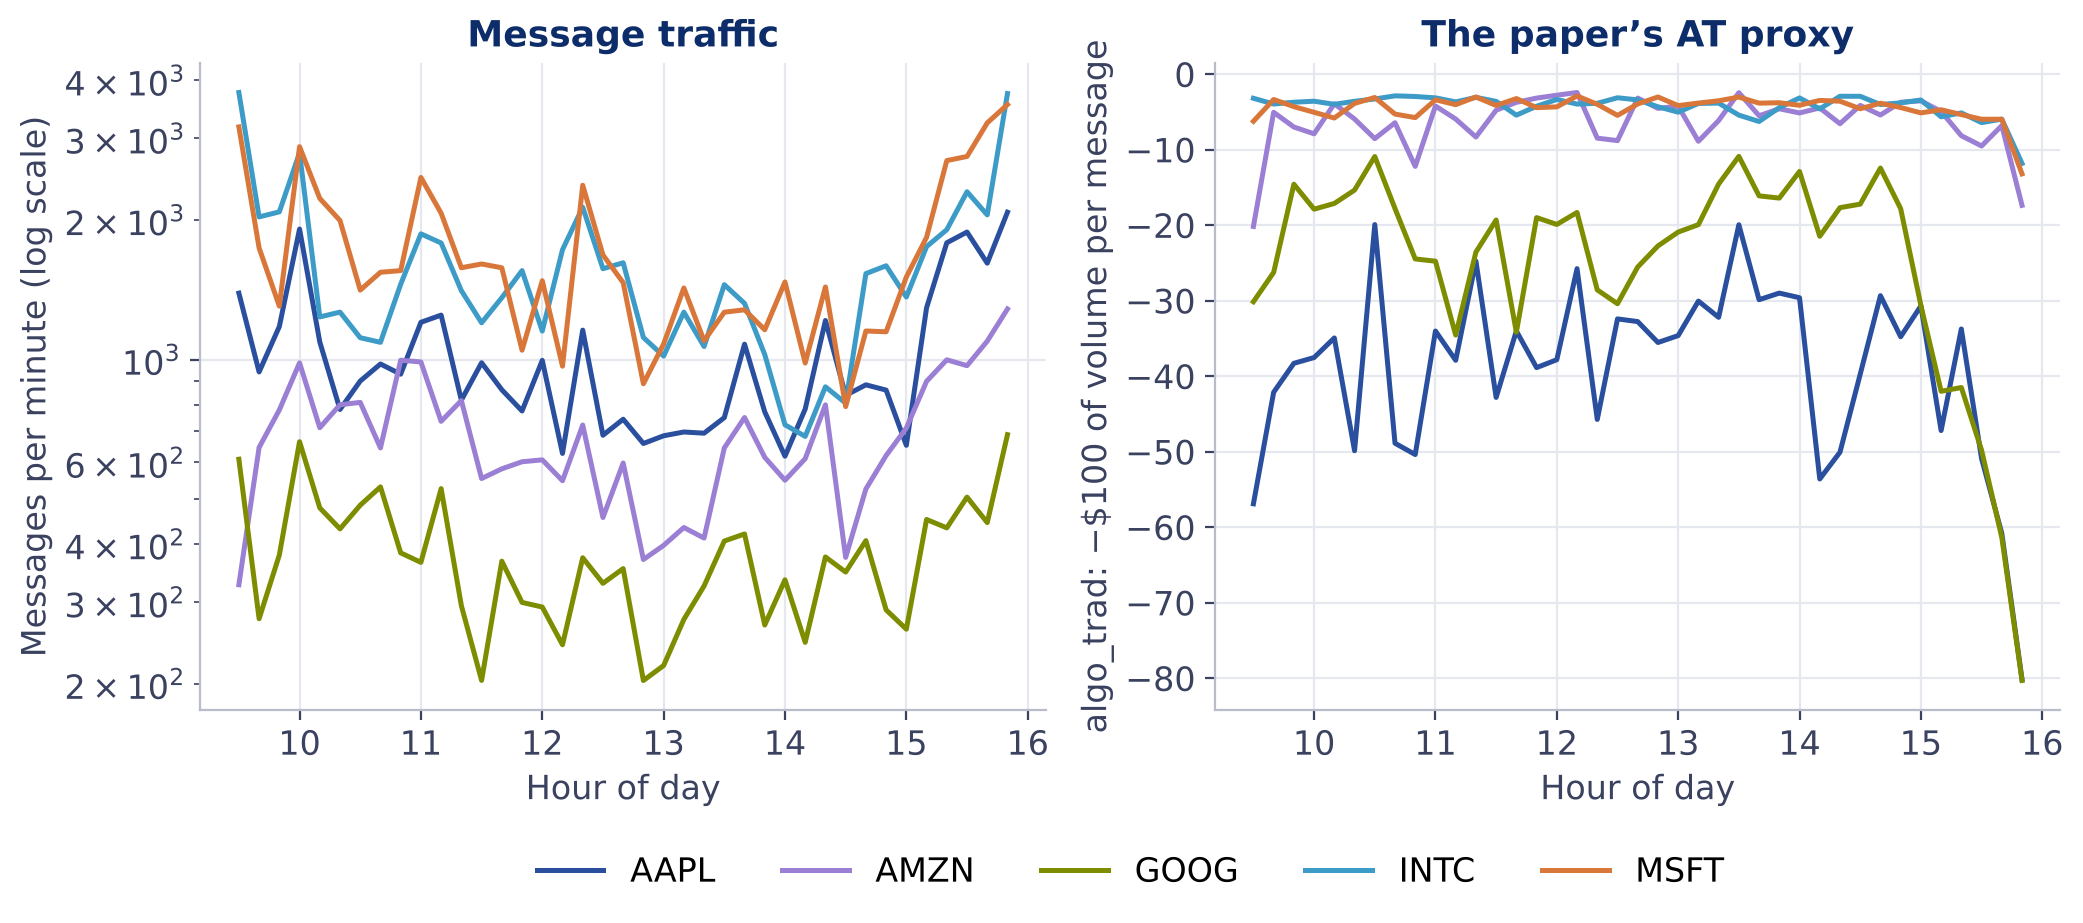

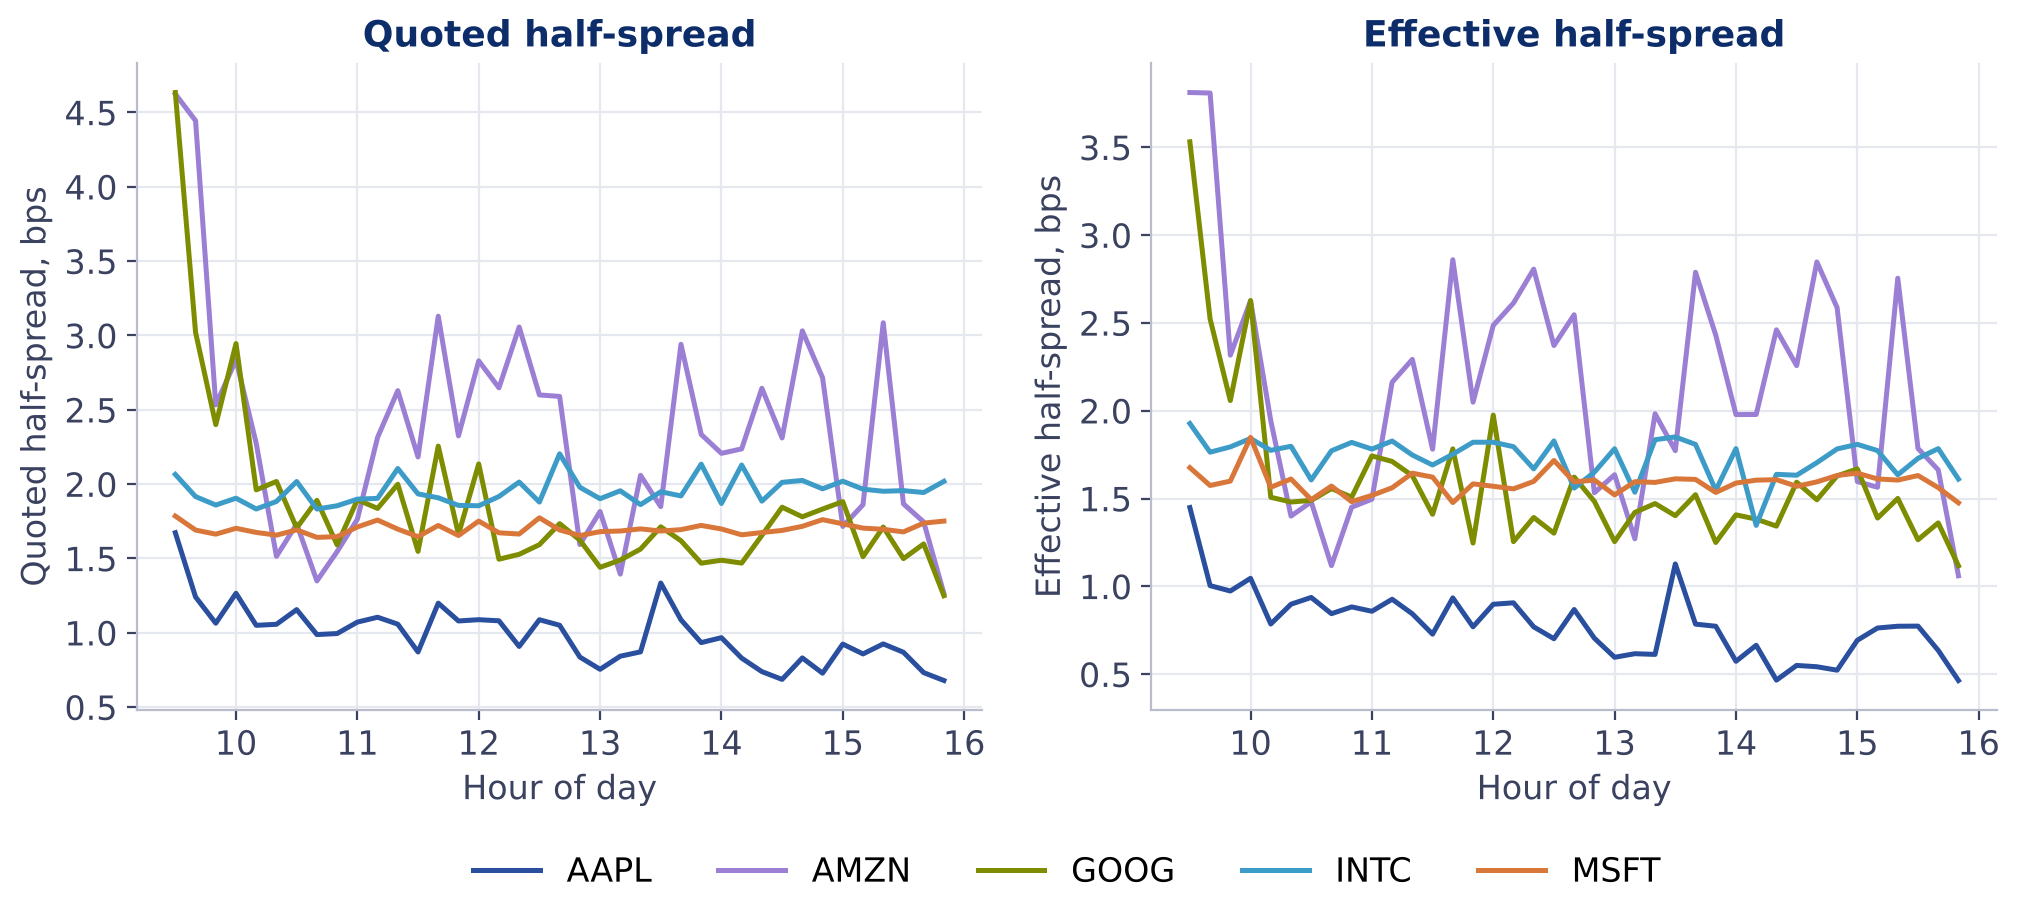

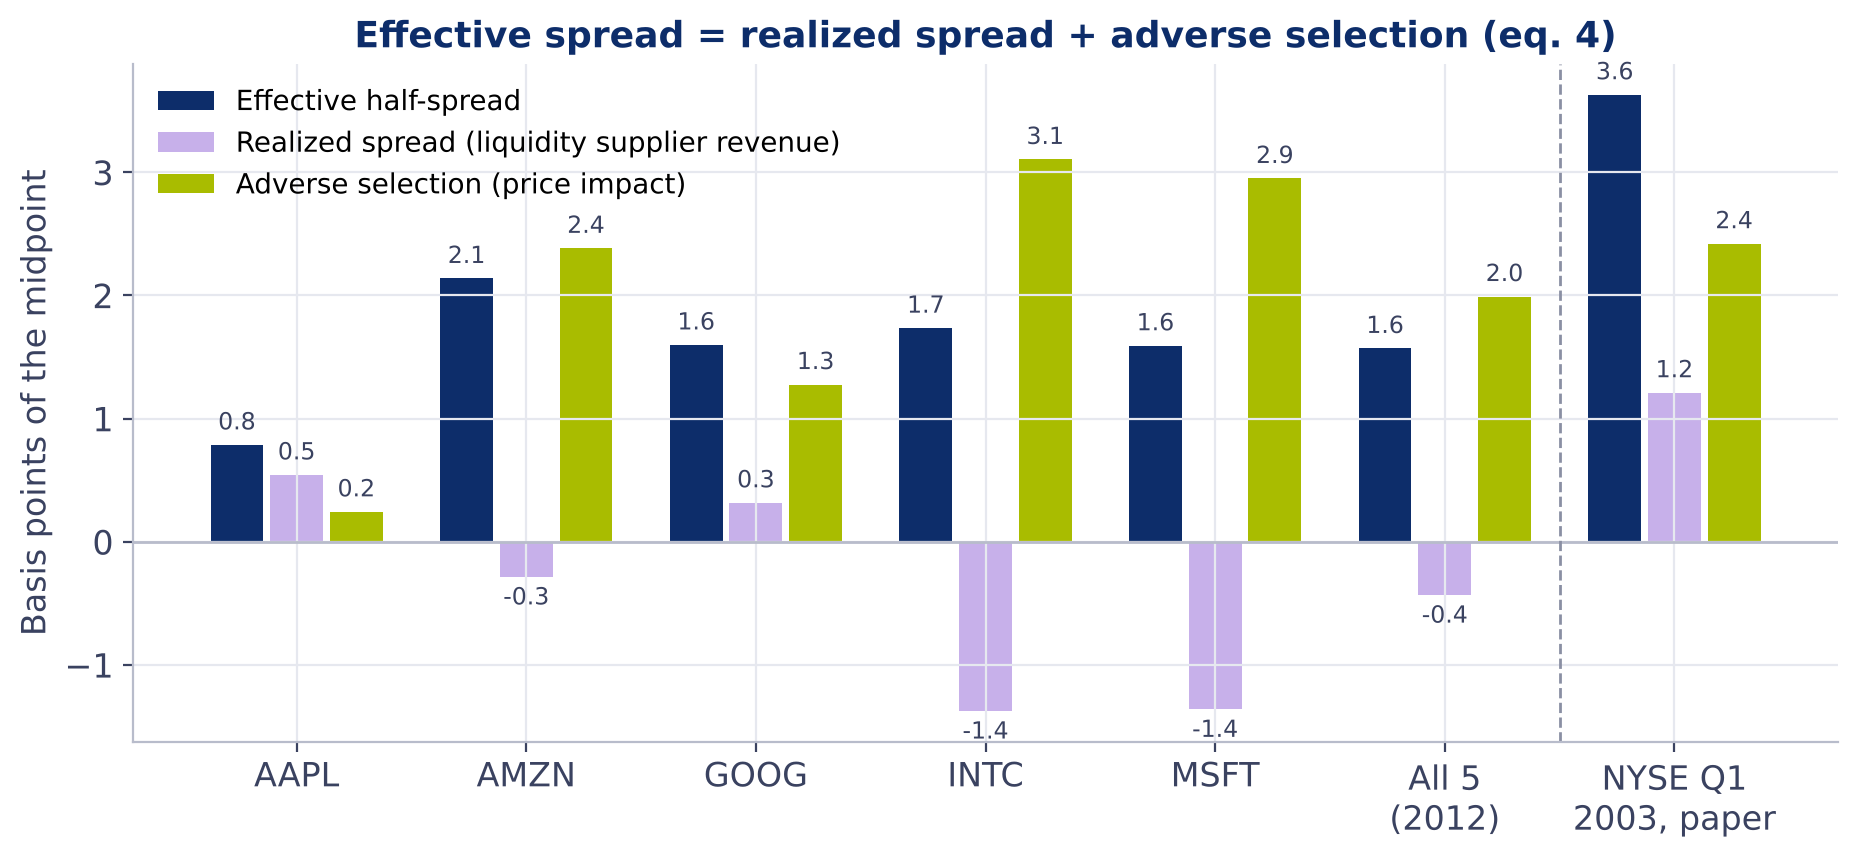

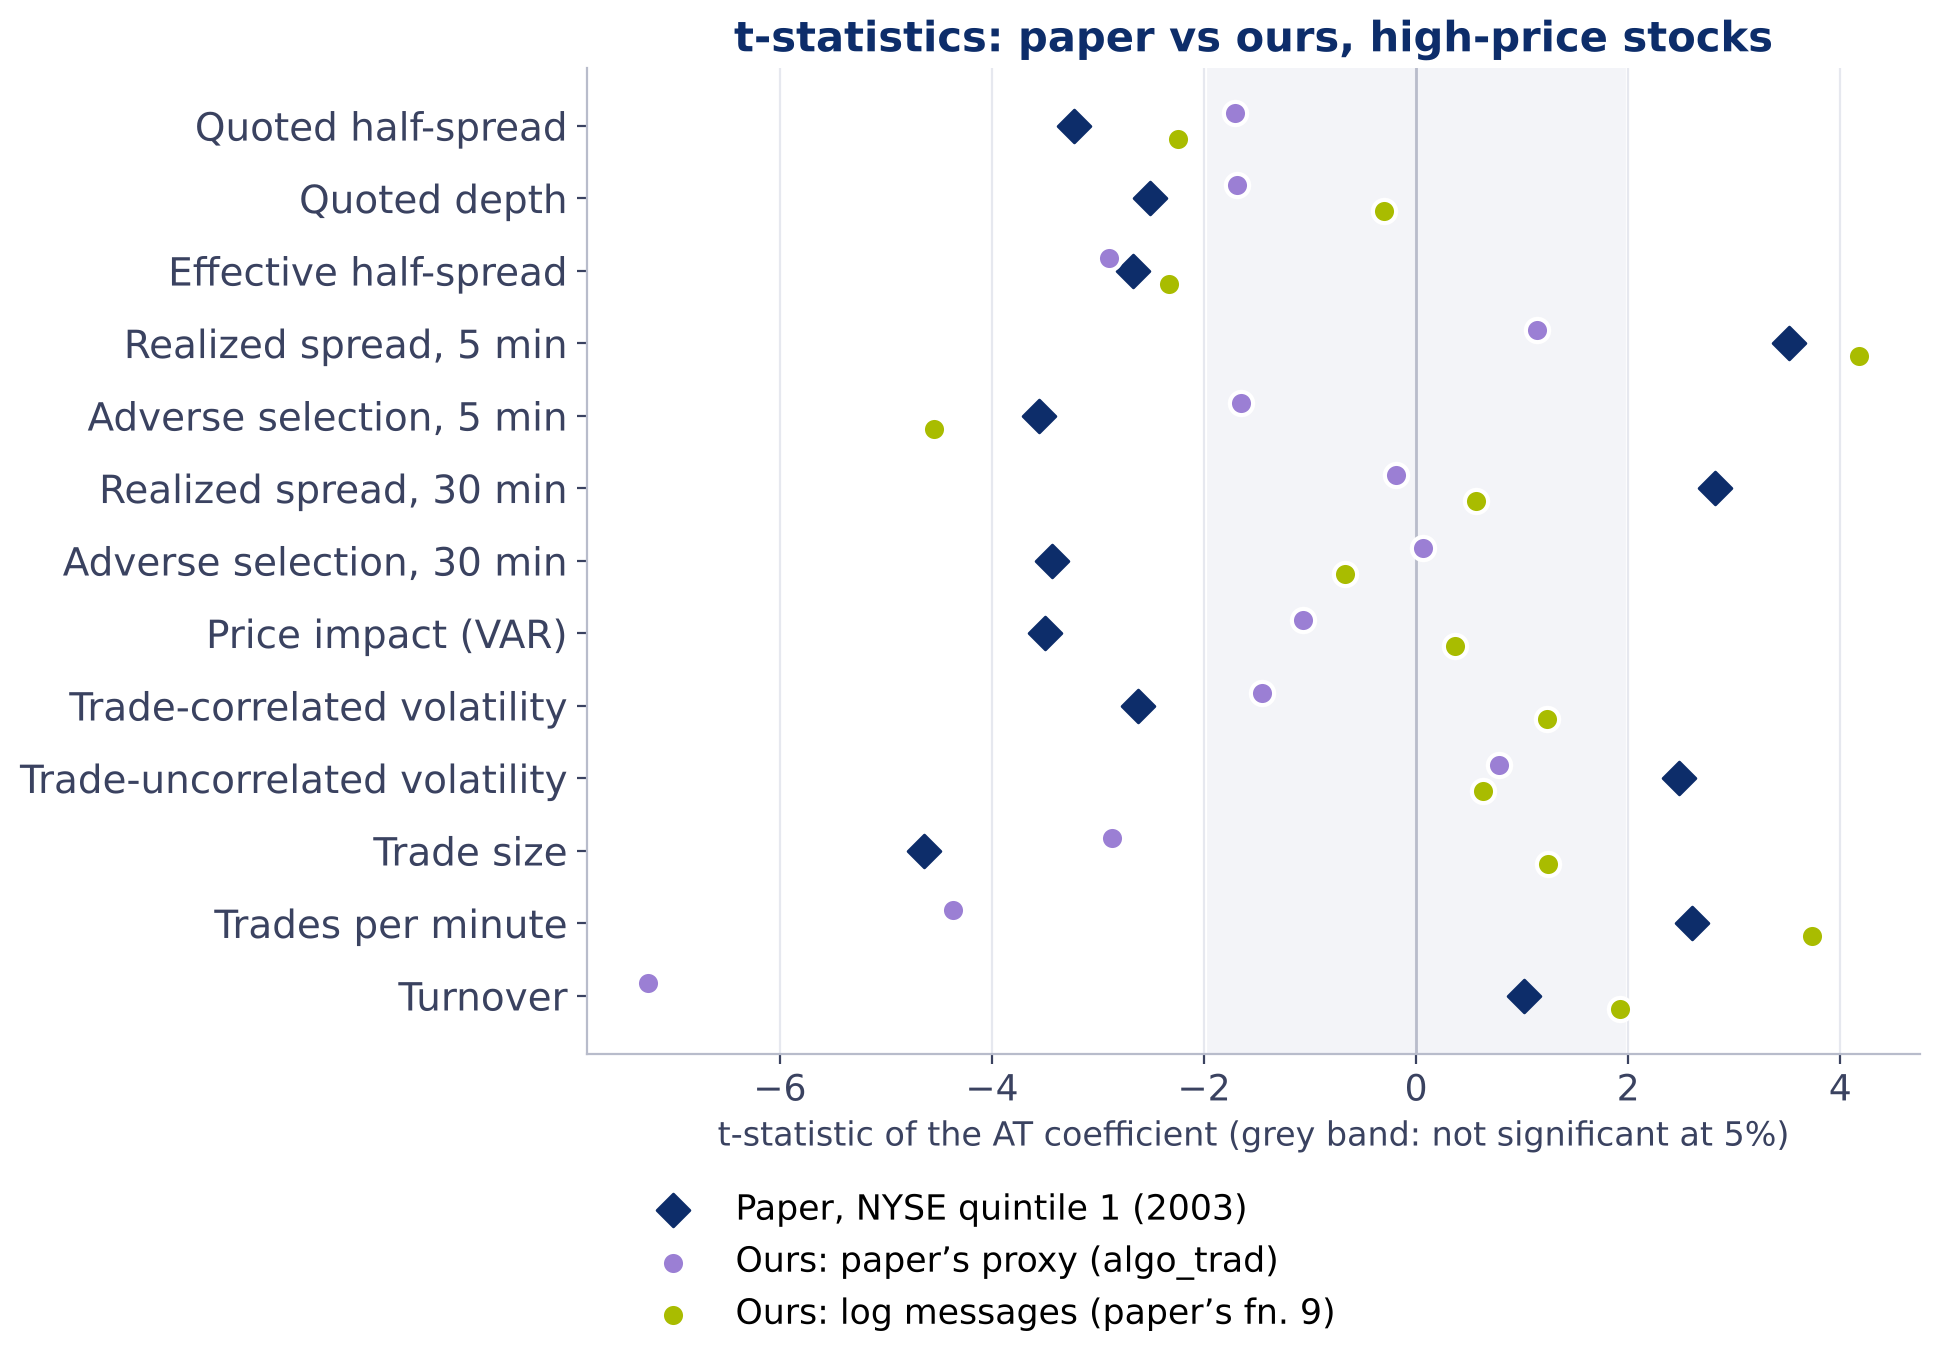

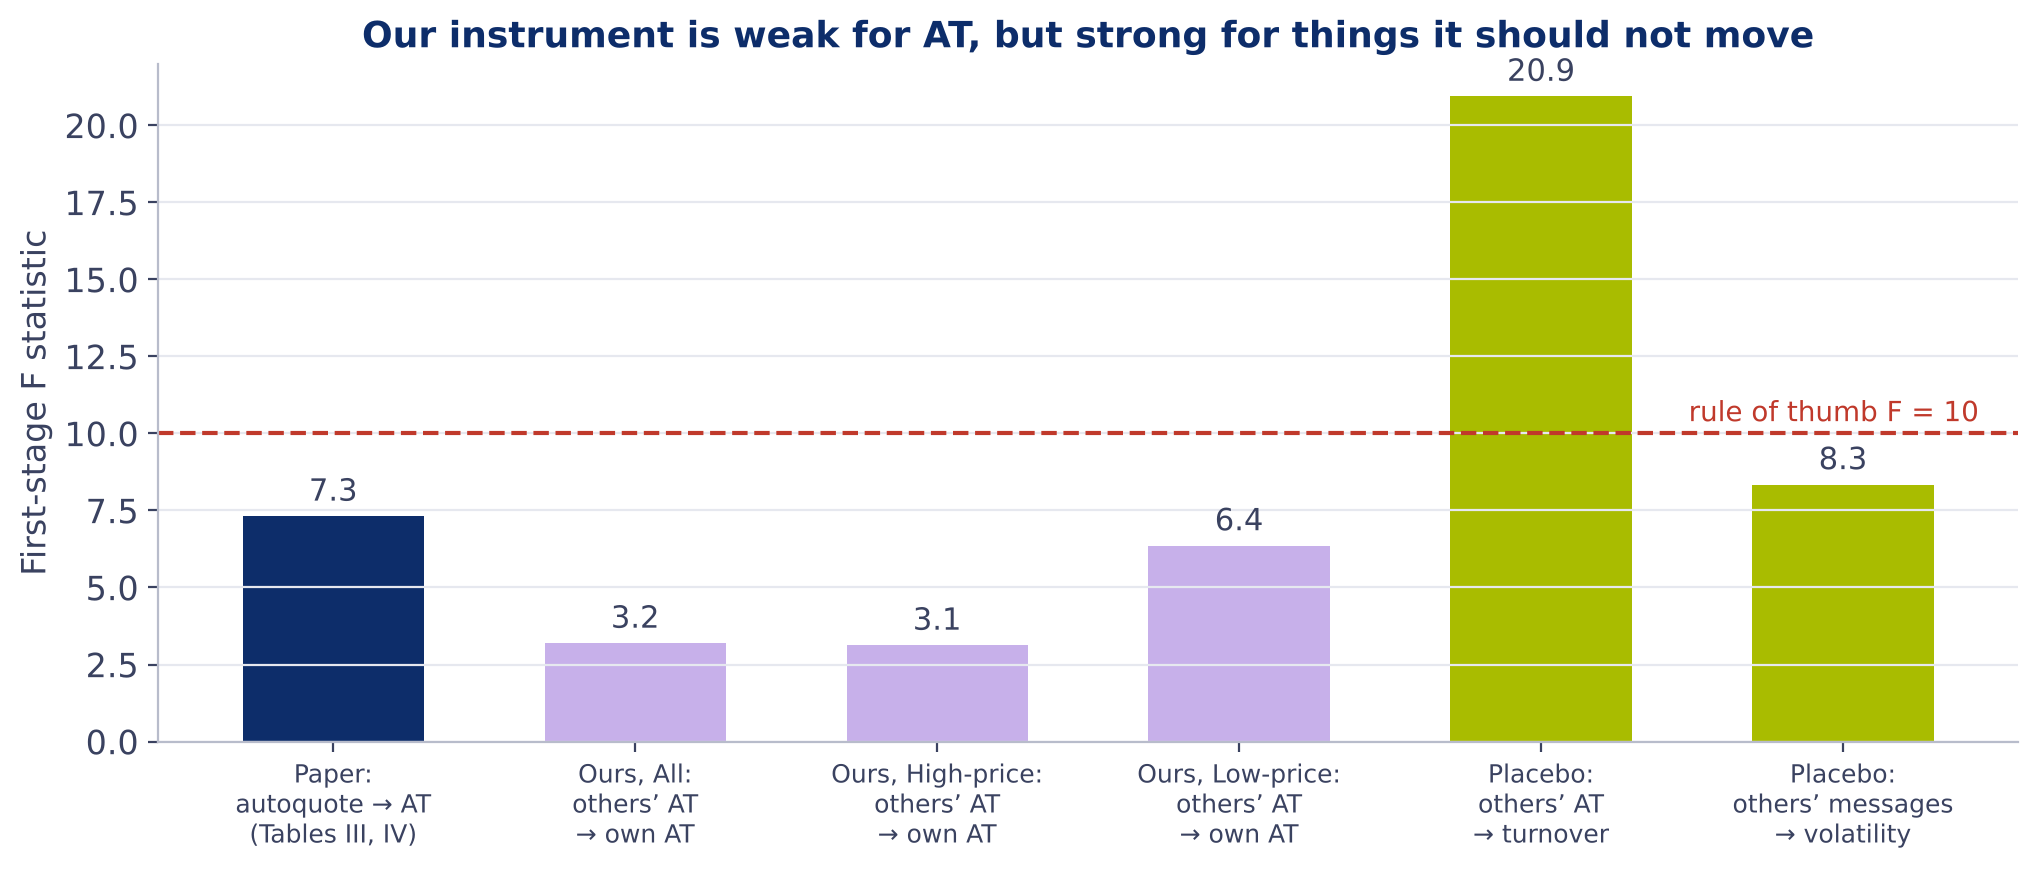

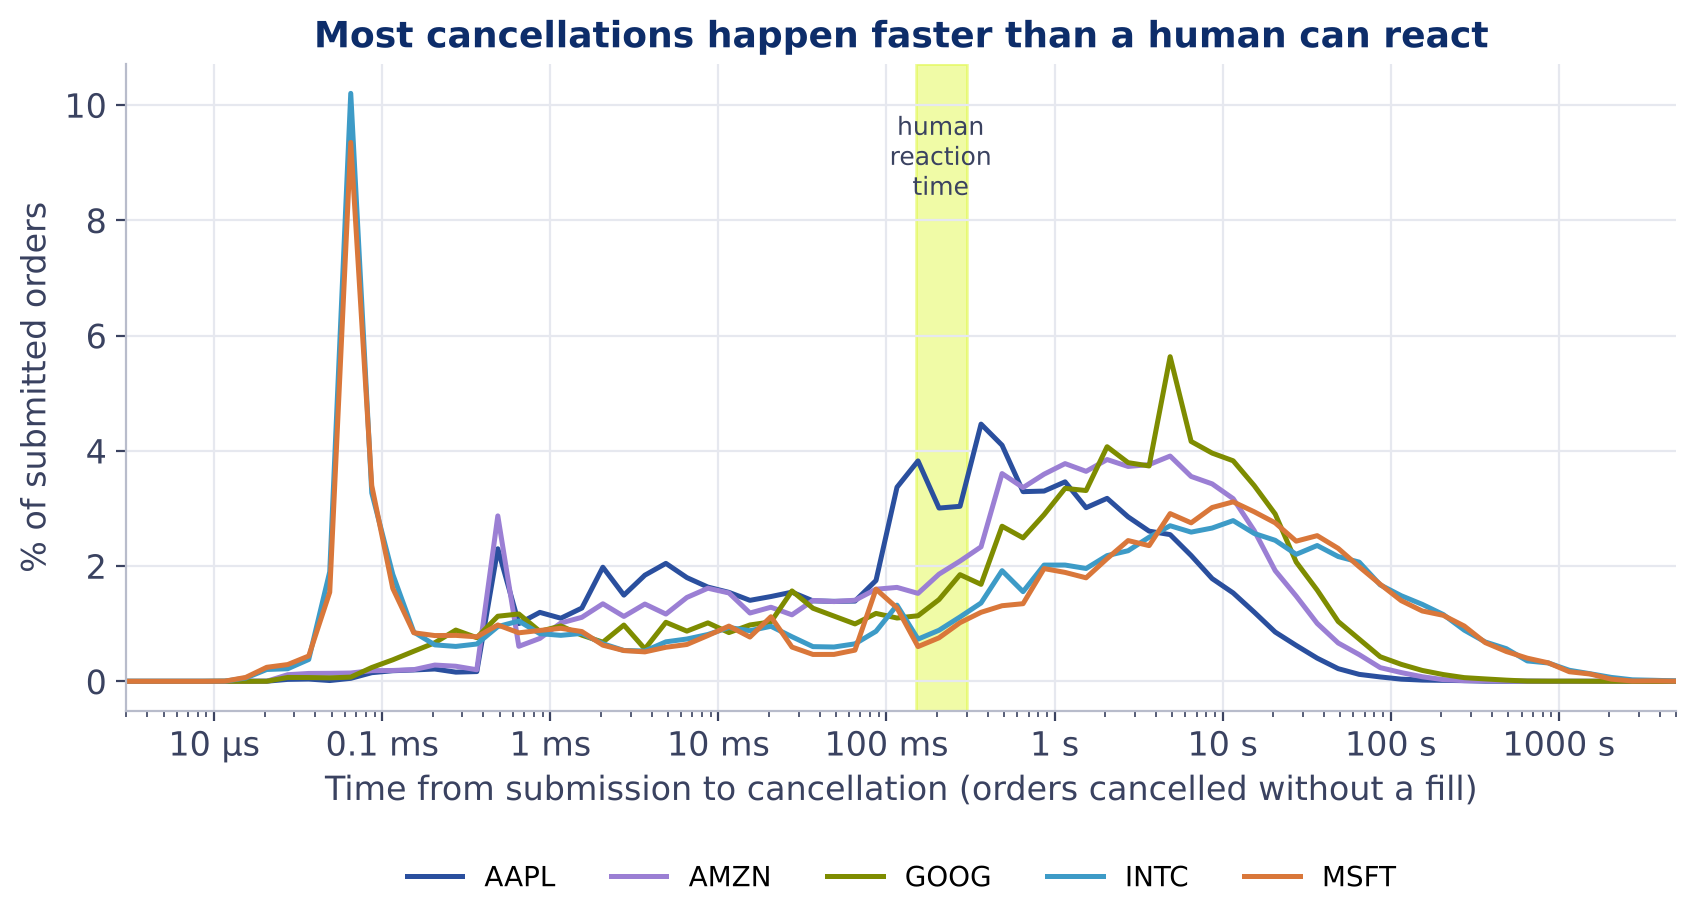

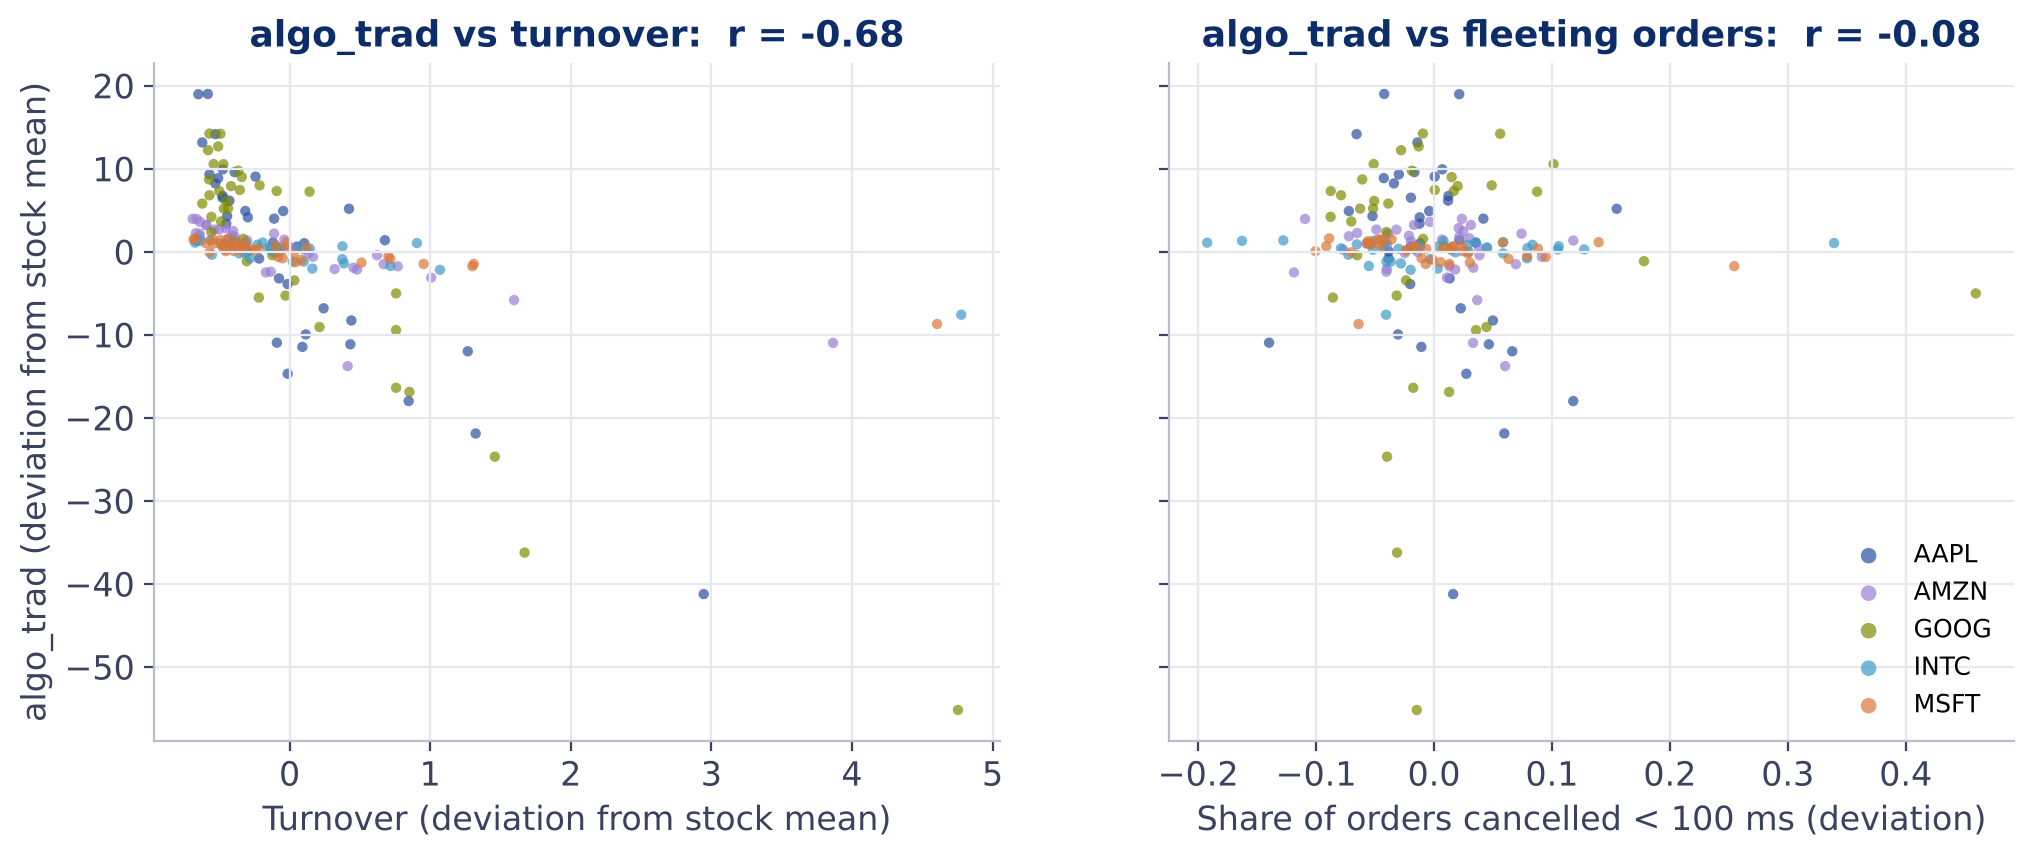

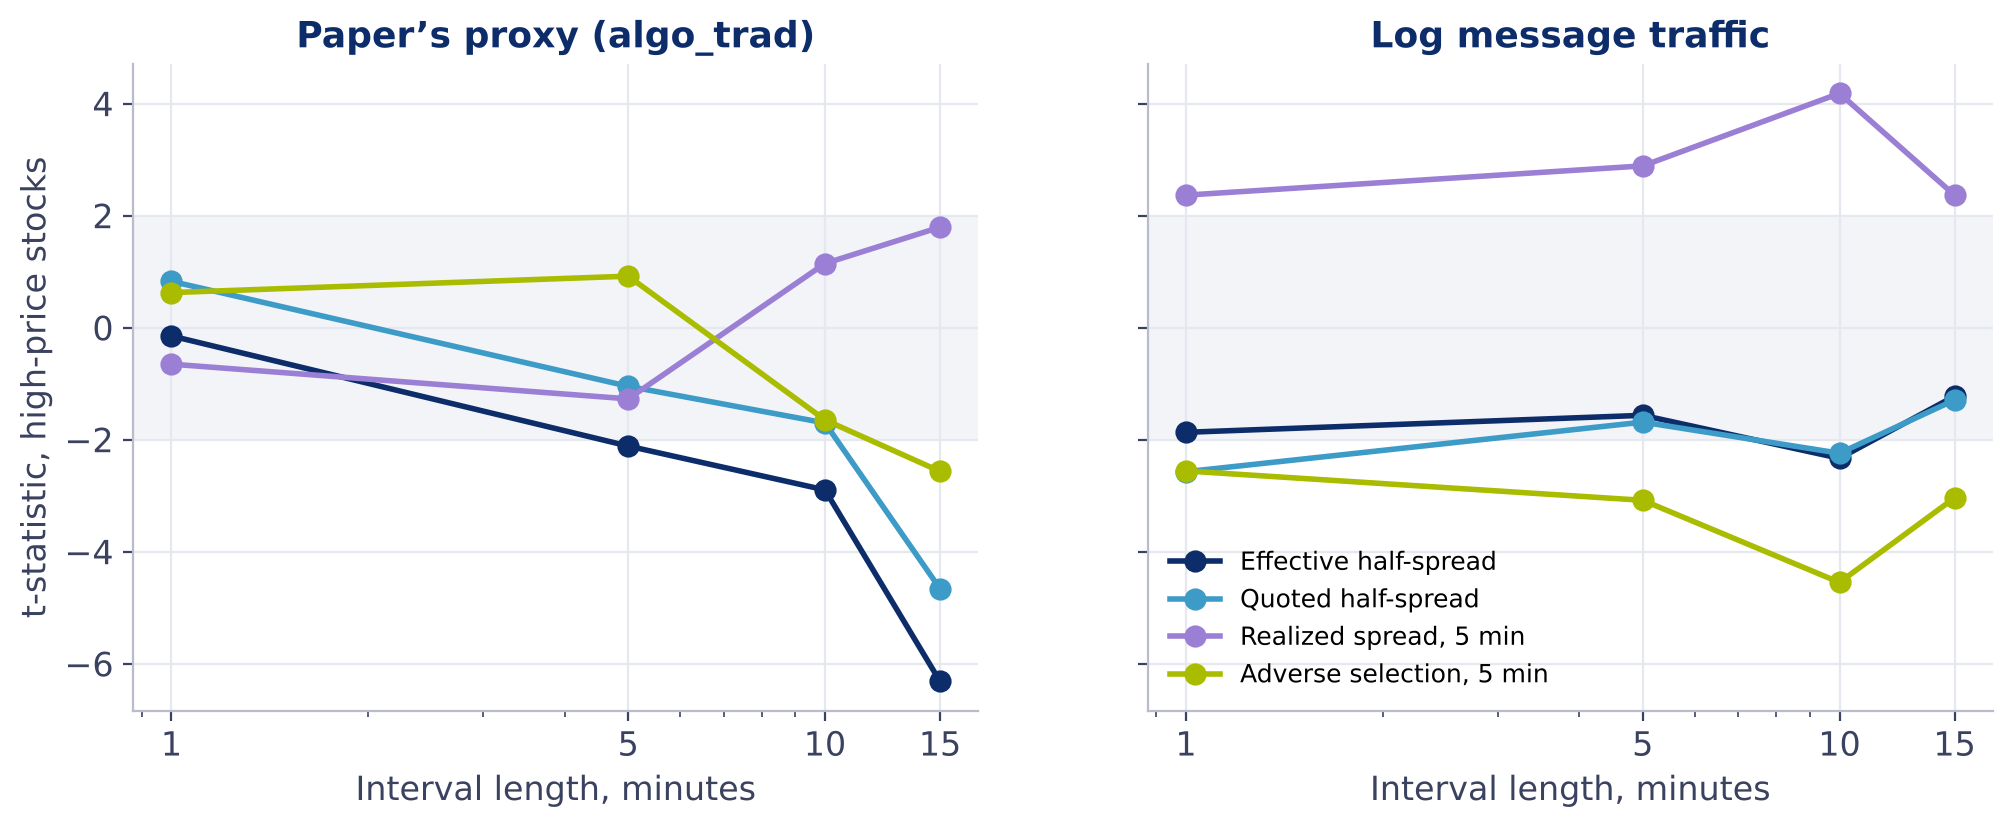

In [19]:
from IPython.display import Image, display
for name in ['intraday_activity','intraday_spreads','spread_decomposition','coef_comparison',
             'first_stage','order_lifetimes','proxy_validity','width_robustness']:
    display(Image(filename=str(PROJECT / 'figures' / f'{name}.png'), width=900))